AdaBoost Binary Classification using diabetes.csv

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

2. Load the dataset

In [2]:
# Load dataset
df = pd.read_csv("diabetes.csv")

# Display first 5 rows
print(df.head())

# Display dataset information
print("\nDataset Shape:", df.shape)

# Display column names
print("\nColumns:")
print(df.columns)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148           72.0             35    169.5  33.6   
1            1       85           66.0             29    102.5  26.6   
2            8      183           64.0             32    169.5  23.3   
3            1       89           66.0             23     94.0  28.1   
4            0      137           40.0             35    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Dataset Shape: (768, 9)

Columns:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


3. Separate input and output

In [3]:
# Input features
X = df.drop("Outcome", axis=1)

# Target variable
y = df["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (768, 8)
y shape: (768,)


4. Split the dataset

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 614
Testing samples: 154


5. Create a weak learner
AdaBoost works by combining several weak learners.
Here we use a Decision Stump:

In [5]:
weak_learner = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

6. Create AdaBoost classifier

In [6]:
ada = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

7. Train AdaBoost

In [7]:
ada.fit(X_train, y_train)

print("AdaBoost model trained successfully!")

AdaBoost model trained successfully!


8. Make predictions

In [8]:
y_pred = ada.predict(X_test)

print("Predicted values:")
print(y_pred)

Predicted values:
[0 0 0 1 0 0 1 1 0 1 0 1 0 0 1 1 0 0 1 0 0 1 1 1 0 0 0 0 1 0 0 0 0 1 1 1 0
 0 1 0 0 0 0 1 0 1 1 0 1 1 0 1 1 0 0 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1
 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 1 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0
 1 0 1 0 0 1 0 1 0 1 0 0 1 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 1
 0 0 0 0 1 0]


9. Calculate accuracy

In [9]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy =", accuracy)
print("Accuracy (%) =", accuracy * 100)

Accuracy = 0.8636363636363636
Accuracy (%) = 86.36363636363636


10. Confusion Matrix

In [10]:
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[91  9]
 [12 42]]


11. Classification Report

In [11]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.91      0.90       100
           1       0.82      0.78      0.80        54

    accuracy                           0.86       154
   macro avg       0.85      0.84      0.85       154
weighted avg       0.86      0.86      0.86       154



13. Demonstrate prediction on a new patient

In [13]:
new_patient = pd.DataFrame({
    "Pregnancies": [2],
    "Glucose": [120],
    "BloodPressure": [70],
    "SkinThickness": [25],
    "Insulin": [80],
    "BMI": [30.5],
    "DiabetesPedigreeFunction": [0.40],
    "Age": [35]
})

prediction = ada.predict(new_patient)

if prediction[0] == 1:
    print("Prediction: Diabetic")
else:
    print("Prediction: Non-Diabetic")

Prediction: Non-Diabetic


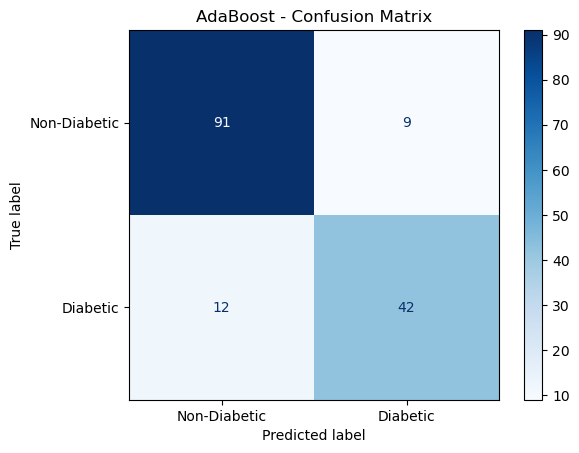

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Diabetic", "Diabetic"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("AdaBoost - Confusion Matrix")
plt.show()

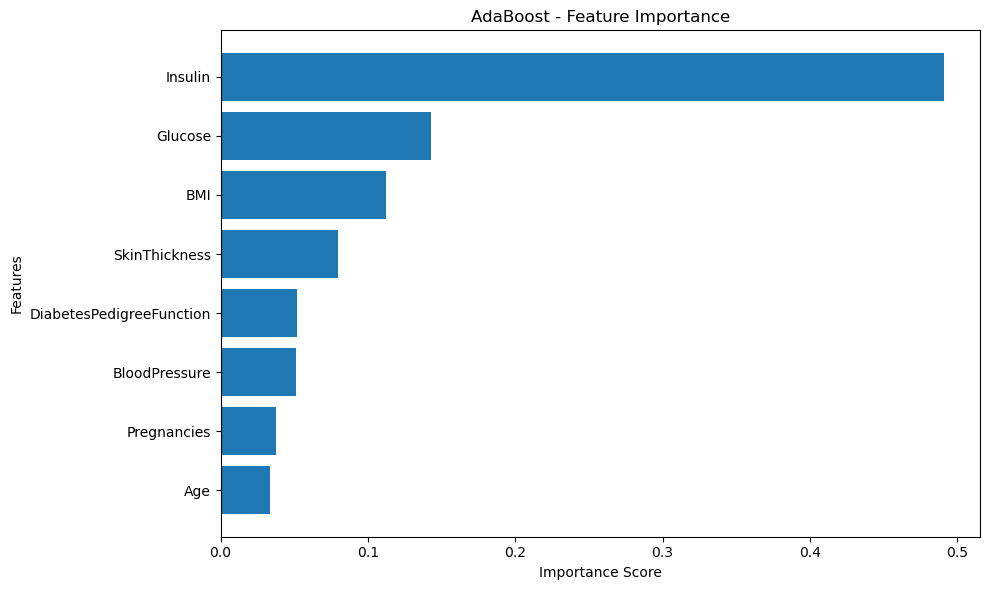

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
importance = ada.feature_importances_

# Create DataFrame
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
}).sort_values(by="Importance", ascending=True)

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("AdaBoost - Feature Importance")
plt.tight_layout()
plt.show()